Actividad para desarrollar — Semana 1: NumPy, Pandas y Matplotlib

**Antes de ejecutar en Google Colab:** abre el panel **Archivos** (icono de carpeta), carga `Ventas_CafeAromaAndino.csv` y luego ejecuta las celdas en orden. Si reinicias el entorno, vuelve a cargar el CSV. El archivo original no se modifica; todas las operaciones se hacen en el DataFrame `df`.


3.1 Carga y exploración inicial de los datos (Pandas)
• Cargue el archivo en un DataFrame con pd.read_csv() y muestre las primeras y últimas filas con head() y
tail().

• Indique el número de filas y columnas con shape y el tipo de dato de cada columna con dtypes. Clasifique
cada variable como numérica o categórica.

• Obtenga las estadísticas descriptivas del DataFrame con df.describe().T

 y explique, en lenguaje de
negocio, qué dicen la media, el mínimo, el máximo y la desviación estándar de las columnas ingresos y
satisfaccion_cliente.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Ventas_CafeAromaAndino.csv")
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'Ventas_CafeAromaAndino.csv'

In [ ]:
df.tail()

,id_registro,semana,sede,unidades_vendidas,precio_unitario,ingresos,inversion_publicidad,clientes_atendidos,satisfaccion_cliente,canal_principal
45,V046,10,Bogotá,412,34200,14090400,2420000,320,4.3,Tienda física
46,V047,10,Medellín,373,33800,12607400,2280000,314,4.6,Web
47,V048,10,Cali,369,31800,11734200,2490000,284,4.0,Tienda física
48,V049,10,Barranquilla,325,30800,10010000,2320000,240,4.0,Domicilio
49,V050,10,Neiva,240,28600,6864000,1740000,191,4.4,Tienda física


In [ ]:
# 2. Número de filas y columnas, y tipos de datos
print("\n--- Dimensiones (shape) ---")
print(df.shape)

print("\n--- Tipos de datos (dtypes) ---")
print(df.dtypes)

# 3. Estadísticas descriptivas
print("\n--- Estadísticas descriptivas (describe) ---")
display(df.describe().T)


--- Dimensiones (shape) ---
(50, 10)

--- Tipos de datos (dtypes) ---
id_registro              object
semana                    int64
sede                     object
unidades_vendidas         int64
precio_unitario           int64
ingresos                  int64
inversion_publicidad      int64
clientes_atendidos        int64
satisfaccion_cliente    float64
canal_principal          object
dtype: object

--- Estadísticas descriptivas (describe) ---


,count,mean,std,min,25%,50%,75%,max
semana,50.0,5.500000e+00,2.901442e+00,1.0,3.000,5.50,8.0,10.0
unidades_vendidas,50.0,3.407000e+02,9.795985e+01,179.0,264.750,330.00,410.5,531.0
precio_unitario,50.0,3.210600e+04,1.696504e+03,28600.0,30875.000,32250.00,33375.0,35500.0
ingresos,50.0,1.107466e+07,3.618249e+06,5280500.0,8221400.000,10675050.00,14014350.0,17894700.0
inversion_publicidad,50.0,2.383400e+06,6.775394e+05,1160000.0,1870000.000,2370000.00,2767500.0,4120000.0
clientes_atendidos,50.0,2.696400e+02,7.893494e+01,145.0,206.000,263.00,323.0,418.0
satisfaccion_cliente,50.0,4.276000e+00,3.100757e-01,3.7,4.025,4.35,4.5,4.9


| Variable | Clasificación |
|---|---|
| `id_registro` | Categórica: identificador |
| `semana` | Numérica discreta |
| `sede` | Categórica nominal |
| `unidades_vendidas` | Numérica discreta |
| `precio_unitario` | Numérica cuantitativa |
| `ingresos` | Numérica cuantitativa |
| `inversion_publicidad` | Numérica cuantitativa |
| `clientes_atendidos` | Numérica discreta |
| `satisfaccion_cliente` | Numérica, escala de valoración |
| `canal_principal` | Categórica nominal |

INGRESOS:

Media: 11.074.664 COP Representa el promedio de ingresos generado por sede en una semana típica, sirviendo como línea base de rendimiento financiero.

Mínimo 5.280.500 COP y Máximo 17.894.700 COP: Muestran la brecha entre la semana de menor facturación y el pico comercial histórico de la cadena, evidenciando la volatilidad o estacionalidad del negocio.

Desviación estándar: 3.618.249 COP Mide qué tan dispersos están los ingresos respecto al promedio; un valor alto indica fluctuaciones importantes entre semanas o sedes que requieren control gerencial.



SATISFACCION DEL CLIENTE :

Media: Indica la percepción general del servicio y calidad del café en una escala de 1.0 a 5.0

Mínimo y Máximo: Permiten identificar si existen caídas críticas de calidad en semanas específicas o experiencias de excelencia.

Desviación estándar: Refleja la consistencia en la experiencia del cliente; una desviación baja denota un estándar de servicio uniforme en las tiendas.

3.2 ANALISIS ESTADISTICO CON NUMPY

• Convierta las columnas ingresos, unidades_vendidas y satisfaccion_cliente en arreglos de NumPy (por
ejemplo, df["ingresos"].to_numpy()) y calcule para cada una el mínimo, el máximo, la suma, la media y la
mediana con np.min(), np.max(), np.sum(), np.mean() y np.median().


• Compare la media y la mediana de los ingresos y explique qué significa la diferencia entre ambas. Luego,
para la sede Cali, identifique la semana cuyos ingresos se alejan notablemente de su propio promedio: ¿se
trata de un dato atípico? ¿qué pudo haber ocurrido esa semana y qué decisión podría tomar la gerencia a
partir de él?


• Usando una condición sobre la columna sede (por ejemplo, df[df["sede"] == "Neiva"]), calcule con
np.sum() los ingresos totales de cada una de las cinco sedes y con np.mean() su satisfacción promedio.


• La empresa planea abrir una sexta sede. Simule con np.random.randint() las unidades vendidas de sus
primeras 10 semanas, usando como rango el mínimo y el máximo de unidades observados en la sede Neiva.
Calcule la media simulada y compárela con la media real de Neiva. Explique por qué el resultado cambia cada
vez que se ejecuta la celda.

In [ ]:
# Conversión a arreglos de NumPy
ingresos_arr = df["ingresos"].to_numpy()
unidades_arr = df["unidades_vendidas"].to_numpy()
satisfaccion_arr = df["satisfaccion_cliente"].to_numpy()

# Métricas con NumPy para Ingresos
print("--- INGRESOS ---")
print(f"Mínimo: {np.min(ingresos_arr):,.2f}")
print(f"Máximo: {np.max(ingresos_arr):,.2f}")
print(f"Suma Total: {np.sum(ingresos_arr):,.2f}")
print(f"Media: {np.mean(ingresos_arr):,.2f}")
print(f"Mediana: {np.median(ingresos_arr):,.2f}")

# Totales y satisfacción promedio por sede
print("\n--- RESUMEN POR SEDE ---")
sedes = ["Bogotá", "Medellín", "Cali", "Barranquilla", "Neiva"]
for s in sedes:
    mask = df["sede"] == s
    ingresos_sede = np.sum(df.loc[mask, "ingresos"].to_numpy())
    satisfaccion_sede = np.mean(df.loc[mask, "satisfaccion_cliente"].to_numpy())
    print(f"Sede {s} -> Ingresos Totales: ${ingresos_sede:,.2f} | Satisfacción Promedio: {satisfaccion_sede:.2f}")

# Comparación de la media y la mediana de los ingresos

ingresos_arr = df["ingresos"].to_numpy()

media_ingresos = np.mean(ingresos_arr)
mediana_ingresos = np.median(ingresos_arr)

diferencia = media_ingresos - mediana_ingresos
diferencia_porcentual = (diferencia / mediana_ingresos) * 100

print("\n--- COMPARACIÓN DE INGRESOS ---")
print(f"Media: ${media_ingresos:,.0f}")
print(f"Mediana: ${mediana_ingresos:,.0f}")
print(f"Diferencia: ${diferencia:,.0f}")
print(f"Diferencia porcentual: {diferencia_porcentual:.2f}%")

# Análisis de la sede Cali
cali = df[df["sede"] == "Cali"].copy()

media_cali = np.mean(cali["ingresos"].to_numpy())

# Identificar la semana más alejada del promedio de Cali
cali["desviacion_absoluta"] = abs(
    cali["ingresos"] - media_cali
)

registro_atipico = cali.loc[
    cali["desviacion_absoluta"].idxmax()
]

# Criterio del rango intercuartílico (IQR)
q1 = cali["ingresos"].quantile(0.25)
q3 = cali["ingresos"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_atipico = (
    registro_atipico["ingresos"] < limite_inferior
    or registro_atipico["ingresos"] > limite_superior
)

print("\n--- ANÁLISIS DE LA SEDE CALI ---")
print(f"Promedio de Cali: ${media_cali:,.0f}")
print(f"Semana identificada: {int(registro_atipico['semana'])}")
print(f"Ingresos: ${registro_atipico['ingresos']:,.0f}")
print(
    f"Diferencia frente al promedio: "
    f"${registro_atipico['desviacion_absoluta']:,.0f}"
)
print(f"¿Es atípico según el criterio IQR?: {es_atipico}")
print(f"Límite superior IQR: ${limite_superior:,.2f}")

# Simulación para la sexta sede (basada en Neiva)
mask_neiva = df["sede"] == "Neiva"
min_neiva = int(np.min(df.loc[mask_neiva, "unidades_vendidas"].to_numpy()))
max_neiva = int(np.max(df.loc[mask_neiva, "unidades_vendidas"].to_numpy()))

unidades_simuladas = np.random.randint(
    min_neiva,
    max_neiva + 1,
    size=10
)
unidades_simuladas = np.random.randint(min_neiva, max_neiva + 1, size=10)
print(f"\n--- SIMULACIÓN SEXTA SEDE (Rango Neiva: {min_neiva}-{max_neiva}) ---")
print(f"Unidades simuladas (10 semanas): {unidades_simuladas}")
print(f"Media simulada: {np.mean(unidades_simuladas):.2f}")
print(f"Media real de Neiva: {np.mean(df.loc[mask_neiva, 'unidades_vendidas'].to_numpy()):.2f}")

--- INGRESOS ---
Mínimo: 5,280,500.00
Máximo: 17,894,700.00
Suma Total: 553,733,200.00
Media: 11,074,664.00
Mediana: 10,675,050.00

--- RESUMEN POR SEDE ---
Sede Bogotá -> Ingresos Totales: $158,581,400.00 | Satisfacción Promedio: 4.30
Sede Medellín -> Ingresos Totales: $133,246,200.00 | Satisfacción Promedio: 4.53
Sede Cali -> Ingresos Totales: $112,593,300.00 | Satisfacción Promedio: 4.09
Sede Barranquilla -> Ingresos Totales: $88,789,200.00 | Satisfacción Promedio: 3.89
Sede Neiva -> Ingresos Totales: $60,523,100.00 | Satisfacción Promedio: 4.57

--- COMPARACIÓN DE INGRESOS ---
Media: $11,074,664
Mediana: $10,675,050
Diferencia: $399,614
Diferencia porcentual: 3.74%

--- ANÁLISIS DE LA SEDE CALI ---
Promedio de Cali: $11,259,330
Semana identificada: 7
Ingresos: $16,076,800
Diferencia frente al promedio: $4,817,470
¿Es atípico según el criterio IQR?: True
Límite superior IQR: $13,297,037.50

--- SIMULACIÓN SEXTA SEDE (Rango Neiva: 179-240) ---
Unidades simuladas (10 semanas): [217 19

La comparación entre la media y la mediana de los ingresos muestra que la media (11.074.664 COP) supera a la mediana (10.675.050 COP) en 399.614. Esta diferencia sugiere que algunos registros con ingresos elevados incrementan el promedio general.

En la sede Cali, la semana 7 registró ingresos de 16.076.800 COP, superando su promedio semanal de 11.259.330 COP en un 42,79 %. Adicionalmente, el registro supera el límite superior calculado mediante el rango intercuartílico, por lo que se considera un posible dato atípico. Este resultado podría relacionarse con un incremento excepcional de la demanda, una campaña comercial o un pedido de volumen elevado, aunque los datos disponibles no permiten confirmar la causa.

Se recomienda revisar las unidades vendidas, los clientes atendidos y la inversión publicitaria de esa semana, así como verificar si existió alguna promoción especial. Si se confirma que el incremento obedeció a una estrategia rentable, la gerencia podría evaluar su aplicación en otras semanas o sedes, mediante pruebas controladas.

## 3.3 Manipulación de datos con Pandas

En este apartado se realizan consultas, filtros, ordenamientos y modificaciones temporales sobre el DataFrame `df`. El archivo CSV original permanece sin cambios.

### 3.3.1 Valores mínimo y máximo de publicidad y clientes atendidos


In [ ]:
# Valores mínimo y máximo de inversión en publicidad y clientes atendidos
columnas_a_revisar = ["inversion_publicidad", "clientes_atendidos"]

for columna in columnas_a_revisar:
    print(f"{columna}:")
    print(f"  Mínimo: {df[columna].min():,}")
    print(f"  Máximo: {df[columna].max():,}")
    print()


inversion_publicidad:
  Mínimo: 1,160,000
  Máximo: 4,120,000

clientes_atendidos:
  Mínimo: 145
  Máximo: 418



En los registros analizados, la inversión publicitaria semanal oscila entre 1.160.000 COP y 4.120.000 COP, mientras que los clientes atendidos varían entre **145 y 418**. Estos rangos muestran diferencias en el tamaño de la operación y en los recursos destinados a promoción. Conviene revisar las semanas con mayor inversión junto con sus ingresos, sin asumir que una inversión alta por sí sola garantiza mejores resultados.


### 3.3.2 Tres filtros de registros

Se aplican los filtros solicitados: una sede elegida por el grupo (Cali), ingresos superiores al promedio general y canal principal Web. En cada caso se informa el número de filas que devuelve y la pregunta de negocio que permite responder.


In [ ]:
# Promedio general de ingresos usado como referencia para el segundo filtro
promedio_general = df["ingresos"].mean()

# (a) Registros de una sede elegida: Cali
filtro_cali = df[df["sede"] == "Cali"]

# (b) Registros cuyo ingreso supera el promedio general
filtro_ingresos_superiores = df[df["ingresos"] > promedio_general]

# (c) Registros cuyo canal principal fue Web
filtro_web = df[df["canal_principal"] == "Web"]

columnas_mostrar = ["id_registro", "semana", "sede", "ingresos", "canal_principal"]

print(f"Promedio general de ingresos: ${promedio_general:,.0f} COP\n")
print(f"(a) Filtro sede Cali: {len(filtro_cali)} filas. Pregunta: ¿cómo se comportaron los registros semanales de Cali?")
display(filtro_cali[columnas_mostrar])

print(f"(b) Ingresos superiores al promedio: {len(filtro_ingresos_superiores)} filas. Pregunta: ¿qué semanas y sedes superaron la referencia de ingresos de la cadena?")
display(filtro_ingresos_superiores[columnas_mostrar])

print(f"(c) Canal Web: {len(filtro_web)} filas. Pregunta: ¿en cuántas semanas Web fue el canal principal y en qué sedes ocurrió?")
display(filtro_web[columnas_mostrar])


Promedio general de ingresos: $11,074,664 COP

(a) Filtro sede Cali: 10 filas. Pregunta: ¿cómo se comportaron los registros semanales de Cali?


,id_registro,semana,sede,ingresos,canal_principal
2,V003,1,Cali,10368000,Tienda física
7,V008,2,Cali,10722600,Domicilio
12,V013,3,Cali,10560900,Tienda física
17,V018,4,Cali,9352200,Domicilio
22,V023,5,Cali,10627500,Domicilio
27,V028,6,Cali,10169700,Tienda física
32,V033,7,Cali,16076800,Domicilio
37,V038,8,Cali,11071600,Domicilio
42,V043,9,Cali,11909800,Domicilio
47,V048,10,Cali,11734200,Tienda física


(b) Ingresos superiores al promedio: 23 filas. Pregunta: ¿qué semanas y sedes superaron la referencia de ingresos de la cadena?


,id_registro,semana,sede,ingresos,canal_principal
0,V001,1,Bogotá,14448000,Domicilio
1,V002,1,Medellín,13786200,Web
5,V006,2,Bogotá,15663600,Tienda física
6,V007,2,Medellín,13460200,Domicilio
10,V011,3,Bogotá,14377500,Domicilio
11,V012,3,Medellín,13284000,Web
15,V016,4,Bogotá,16634400,Tienda física
16,V017,4,Medellín,12080200,Domicilio
20,V021,5,Bogotá,15872700,Tienda física
21,V022,5,Medellín,14295200,Tienda física


(c) Canal Web: 7 filas. Pregunta: ¿en cuántas semanas Web fue el canal principal y en qué sedes ocurrió?


,id_registro,semana,sede,ingresos,canal_principal
1,V002,1,Medellín,13786200,Web
11,V012,3,Medellín,13284000,Web
14,V015,3,Neiva,5949400,Web
28,V029,6,Barranquilla,8359200,Web
29,V030,6,Neiva,5907300,Web
41,V042,9,Medellín,13479200,Web
46,V047,10,Medellín,12607400,Web


El filtro de Cali devuelve **10 filas**, una por cada semana registrada para esa sede. **23 registros** superan el promedio general de ingresos de $11.074.664 COP, por lo que pueden estudiarse para identificar las sedes y semanas de mayor desempeño. El canal Web aparece como principal en **7 registros**; esto describe la frecuencia con la que fue el canal predominante, pero no significa que las ventas Web sean solo 7 transacciones, ya que cada fila resume una sede durante una semana.


### 3.3.3 Cinco mayores ingresos y cinco menores satisfacciones


In [ ]:
# Cinco registros con mayores ingresos
top_5_ingresos = df.sort_values(by="ingresos", ascending=False).head(5)

# Cinco registros con menor satisfacción del cliente
top_5_menor_satisfaccion = df.sort_values(by="satisfaccion_cliente", ascending=True).head(5)

columnas_ingresos = ["id_registro", "semana", "sede", "ingresos", "satisfaccion_cliente"]
columnas_satisfaccion = ["id_registro", "semana", "sede", "satisfaccion_cliente", "ingresos"]

print("--- Cinco registros con mayores ingresos ---")
display(top_5_ingresos[columnas_ingresos])
print("Sedes en la lista de mayores ingresos:")
print(top_5_ingresos["sede"].value_counts())

print("\n--- Cinco registros con menor satisfacción ---")
display(top_5_menor_satisfaccion[columnas_satisfaccion])
print("Sedes en la lista de menor satisfacción:")
print(top_5_menor_satisfaccion["sede"].value_counts())


--- Cinco registros con mayores ingresos ---


,id_registro,semana,sede,ingresos,satisfaccion_cliente
40,V041,9,Bogotá,17894700,4.1
30,V031,7,Bogotá,17643600,4.5
15,V016,4,Bogotá,16634400,4.4
35,V036,8,Bogotá,16286000,4.5
32,V033,7,Cali,16076800,4.2


Sedes en la lista de mayores ingresos:
sede
Bogotá    4
Cali      1
Name: count, dtype: int64

--- Cinco registros con menor satisfacción ---


,id_registro,semana,sede,satisfaccion_cliente,ingresos
28,V029,6,Barranquilla,3.7,8359200
23,V024,5,Barranquilla,3.7,9484800
42,V043,9,Cali,3.7,11909800
8,V009,2,Barranquilla,3.8,10048500
38,V039,8,Barranquilla,3.8,8210400


Sedes en la lista de menor satisfacción:
sede
Barranquilla    4
Cali            1
Name: count, dtype: int64


Entre los cinco registros con más ingresos, **Bogotá aparece cuatro veces** y Cali una vez (semana 7), lo cual destaca el peso comercial de Bogotá y un resultado especialmente alto de Cali en esa semana. En los cinco registros con menor satisfacción, **Barranquilla aparece cuatro veces** y Cali una vez. Esto sugiere priorizar una revisión de la experiencia del cliente en Barranquilla y analizar qué condiciones coincidieron con el resultado destacado de Cali, sin concluir que un solo registro represente el comportamiento habitual de toda la sede.


### 3.3.4 Agregar temporalmente un registro de la semana 11 y eliminarlo

El nuevo registro usa valores plausibles y consistentes: los ingresos corresponden a unidades vendidas multiplicadas por el precio unitario. Se agrega solo al DataFrame durante la demostración y luego se elimina.


In [ ]:
# Guardar el índice donde se agregará temporalmente el registro
indice_nuevo = len(df)

nuevo_registro = {
    "id_registro": "V051",
    "semana": 11,
    "sede": "Neiva",
    "unidades_vendidas": 220,
    "precio_unitario": 29000,
    "ingresos": 220 * 29000,
    "inversion_publicidad": 1650000,
    "clientes_atendidos": 185,
    "satisfaccion_cliente": 4.5,
    "canal_principal": "Tienda física"
}

# Agregar el registro únicamente al DataFrame
df.loc[indice_nuevo] = nuevo_registro
print("DataFrame con el registro de prueba agregado (últimas tres filas):")
display(df.tail(3))
print(f"Número de filas después de agregarlo: {len(df)}")

# Eliminar el registro de prueba y verificar que se recuperan las 50 filas originales
df = df.drop(index=indice_nuevo).reset_index(drop=True)
print("\nDataFrame después de eliminar el registro de prueba (últimas tres filas):")
display(df.tail(3))
print(f"Número de filas después de eliminarlo: {len(df)}")
print("¿El registro V051 permanece en el DataFrame?", (df["id_registro"] == "V051").any())


DataFrame con el registro de prueba agregado (últimas tres filas):


,id_registro,semana,sede,unidades_vendidas,precio_unitario,ingresos,inversion_publicidad,clientes_atendidos,satisfaccion_cliente,canal_principal
48,V049,10,Barranquilla,325,30800,10010000,2320000,240,4.0,Domicilio
49,V050,10,Neiva,240,28600,6864000,1740000,191,4.4,Tienda física
50,V051,11,Neiva,220,29000,6380000,1650000,185,4.5,Tienda física


Número de filas después de agregarlo: 51

DataFrame después de eliminar el registro de prueba (últimas tres filas):


,id_registro,semana,sede,unidades_vendidas,precio_unitario,ingresos,inversion_publicidad,clientes_atendidos,satisfaccion_cliente,canal_principal
47,V048,10,Cali,369,31800,11734200,2490000,284,4.0,Tienda física
48,V049,10,Barranquilla,325,30800,10010000,2320000,240,4.0,Domicilio
49,V050,10,Neiva,240,28600,6864000,1740000,191,4.4,Tienda física


Número de filas después de eliminarlo: 50
¿El registro V051 permanece en el DataFrame? False


La prueba muestra que Pandas permite incorporar un registro para simular una observación futura y después retirarlo con `drop()`. Al finalizar, el DataFrame vuelve a tener **50 filas** y el identificador `V051` ya no aparece; por tanto, el ejemplo no altera de forma permanente el conjunto de datos original. Los valores de la semana 11 son ilustrativos y no representan ventas reales.


### 3.3.5 Crear `ticket_promedio` e identificar la sede con el promedio más alto


In [ ]:
# Ticket promedio por cliente para cada registro semanal
df["ticket_promedio"] = df["ingresos"] / df["clientes_atendidos"]

# Promedio del ticket semanal por sede, ordenado de mayor a menor
ticket_por_sede = df.groupby("sede")["ticket_promedio"].mean().sort_values(ascending=False)
print("Ticket promedio medio por cliente, según sede (COP):")
display(ticket_por_sede.to_frame(name="ticket_promedio_COP").round(2))

sede_ticket_mayor = ticket_por_sede.idxmax()
valor_ticket_mayor = ticket_por_sede.max()
print(f"\nLa sede con mayor ticket promedio es {sede_ticket_mayor}: ${valor_ticket_mayor:,.2f} COP por cliente.")


Ticket promedio medio por cliente, según sede (COP):


,ticket_promedio_COP
sede,
Bogotá,43018.66
Cali,41794.71
Medellín,41583.94
Barranquilla,40008.05
Neiva,36754.91



La sede con mayor ticket promedio es Bogotá: $43,018.66 COP por cliente.


**Bogotá** registra el mayor ticket promedio medio, cercano a 43.019 COP por cliente. Neiva presenta el valor más bajo, alrededor de $36.755 COP. La gerencia puede revisar la mezcla de productos, precios y comportamiento de compra por sede para comprender la brecha. Este indicador es el ingreso semanal dividido entre los clientes atendidos y luego promediado por sede; no equivale al precio unitario de una bolsa.

## 3.4 Visualización de datos con Matplotlib

Las siguientes gráficas se construyen a partir del DataFrame original de 50 registros. Los ingresos se muestran en millones de pesos colombianos para facilitar la lectura.

### 3.4.1 Gráfica de barras: ingresos totales por sede


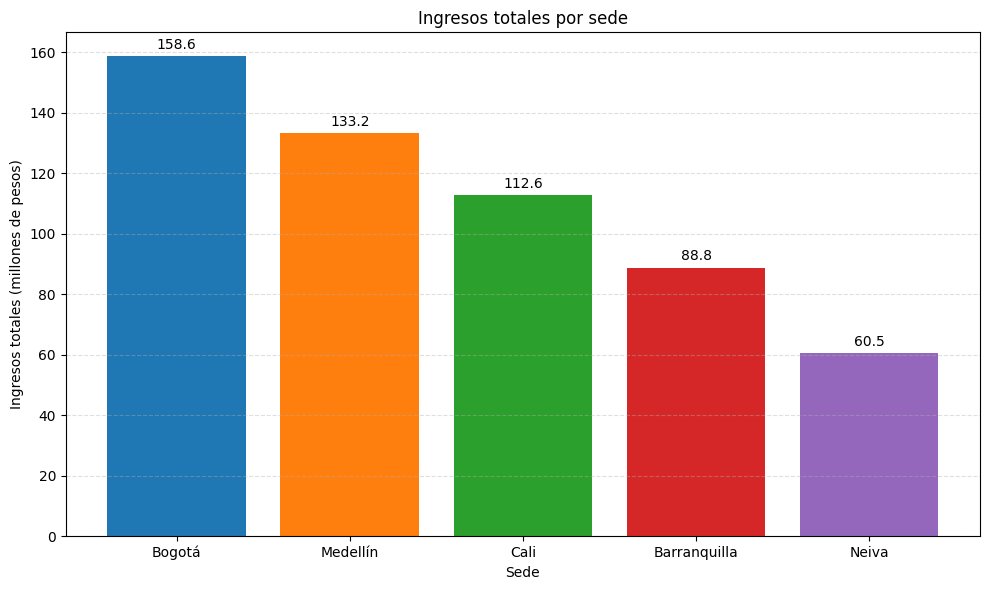

Ingresos totales por sede (COP):
Bogotá: $158,581,400
Medellín: $133,246,200
Cali: $112,593,300
Barranquilla: $88,789,200
Neiva: $60,523,100


In [ ]:
# Sumar los ingresos de cada sede usando NumPy, como en el punto 3.2
sedes = ["Bogotá", "Medellín", "Cali", "Barranquilla", "Neiva"]
ingresos_totales_sede = {
    sede: np.sum(df.loc[df["sede"] == sede, "ingresos"].to_numpy())
    for sede in sedes
}

# Convertir los valores a millones de COP para presentar la gráfica
nombres_sedes = list(ingresos_totales_sede.keys())
ingresos_millones = [valor / 1_000_000 for valor in ingresos_totales_sede.values()]

plt.figure(figsize=(10, 6))
barras = plt.bar(nombres_sedes, ingresos_millones, color=["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"])
plt.title("Ingresos totales por sede")
plt.xlabel("Sede")
plt.ylabel("Ingresos totales (millones de pesos)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.bar_label(barras, fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

print("Ingresos totales por sede (COP):")
for sede, valor in sorted(ingresos_totales_sede.items(), key=lambda elemento: elemento[1], reverse=True):
    print(f"{sede}: ${valor:,.0f}")


Bogotá lidera los ingresos acumulados con 158.581.400 COP, seguida de Medellín con 133.246.200 COP y Cali con 112.593.300 COP. Barranquilla suma 88.789.200 COP y Neiva 60.523.100 COP. La diferencia muestra que las sedes tienen escalas comerciales distintas; antes de redistribuir presupuesto, conviene considerar también costos, rentabilidad, tamaño del mercado y satisfacción, no solo los ingresos.


### 3.4.2 Gráfica de líneas: evolución semanal de ingresos en dos sedes


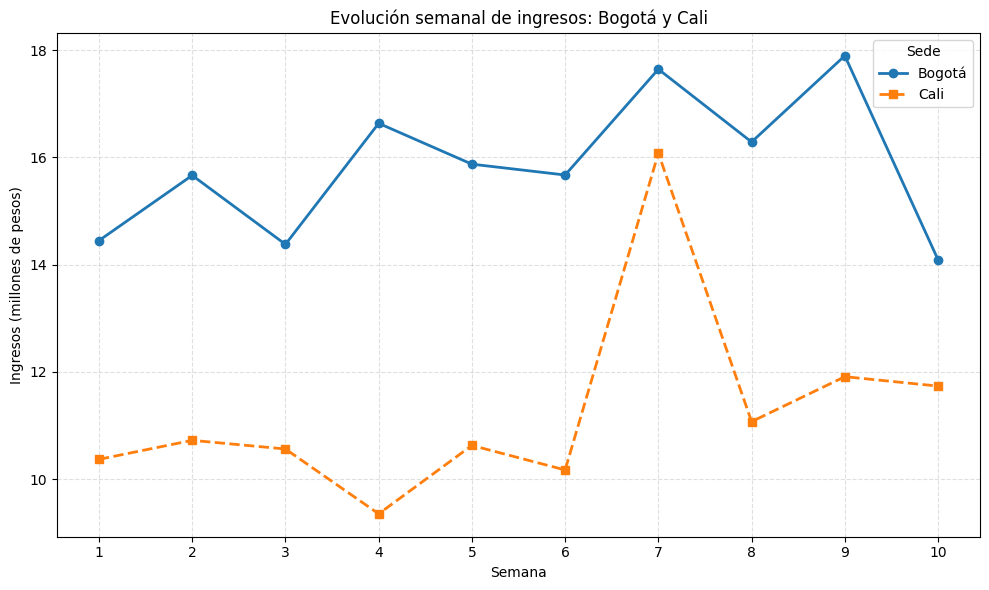

In [ ]:
# Comparar la evolución semanal de Bogotá y Cali
plt.figure(figsize=(10, 6))

for sede, color, estilo, marcador in [("Bogotá", "tab:blue", "-", "o"), ("Cali", "tab:orange", "--", "s")]:
    datos_sede = df[df["sede"] == sede].sort_values("semana")
    plt.plot(
        datos_sede["semana"],
        datos_sede["ingresos"] / 1_000_000,
        color=color,
        linestyle=estilo,
        marker=marcador,
        linewidth=2,
        label=sede
    )

plt.title("Evolución semanal de ingresos: Bogotá y Cali")
plt.xlabel("Semana")
plt.ylabel("Ingresos (millones de pesos)")
plt.xticks(range(1, 11))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Sede")
plt.tight_layout()
plt.show()


Bogotá mantiene ingresos semanales superiores a Cali en la mayoría de los periodos y alcanza su mayor ingreso en la semana 9. Cali presenta un pico marcado en la semana 7 (aproximadamente **$16,08 millones COP**), seguido de una reducción en la semana 8. Es pertinente revisar si ese pico coincidió con una campaña, una venta extraordinaria o alguna condición operativa antes de usarlo como referencia de pronóstico.


### 3.4.3 Nube de puntos: inversión en publicidad frente a ingresos


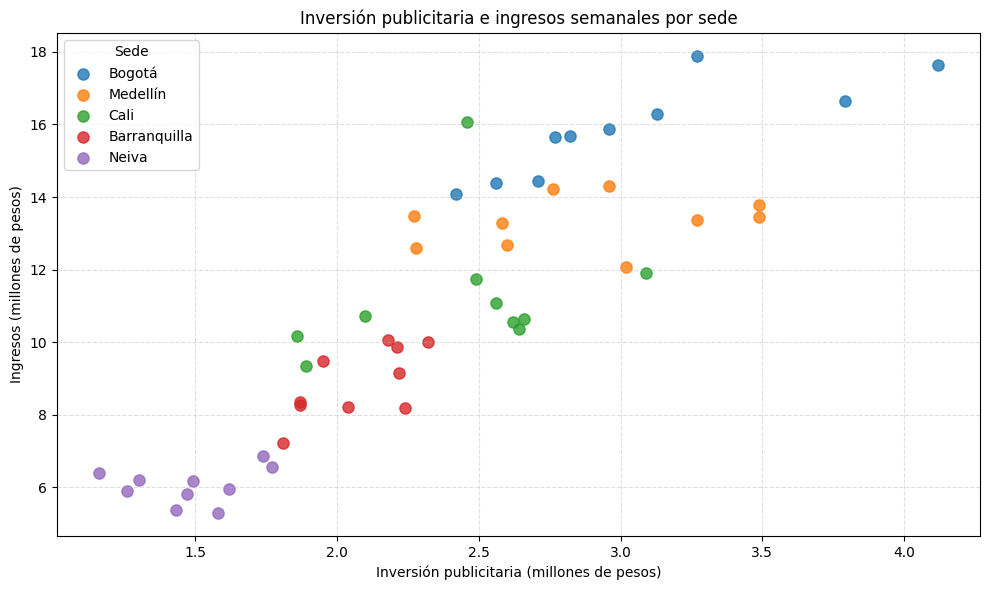

Correlación de Pearson entre publicidad e ingresos: 0.871


In [ ]:
# Dispersión: inversión publicitaria en X e ingresos en Y; un color por sede
colores_sedes = {
    "Bogotá": "tab:blue",
    "Medellín": "tab:orange",
    "Cali": "tab:green",
    "Barranquilla": "tab:red",
    "Neiva": "tab:purple"
}

plt.figure(figsize=(10, 6))
for sede in sedes:
    datos_sede = df[df["sede"] == sede]
    plt.scatter(
        datos_sede["inversion_publicidad"] / 1_000_000,
        datos_sede["ingresos"] / 1_000_000,
        color=colores_sedes[sede],
        label=sede,
        alpha=0.8,
        s=65
    )

plt.title("Inversión publicitaria e ingresos semanales por sede")
plt.xlabel("Inversión publicitaria (millones de pesos)")
plt.ylabel("Ingresos (millones de pesos)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Sede")
plt.tight_layout()
plt.show()

correlacion_publicidad_ingresos = df["inversion_publicidad"].corr(df["ingresos"])
print(f"Correlación de Pearson entre publicidad e ingresos: {correlacion_publicidad_ingresos:.3f}")


En el conjunto analizado se observa una asociación positiva entre inversión publicitaria e ingresos; el coeficiente de correlación de Pearson es aproximadamente **0,871**, lo cual indica una relación lineal positiva marcada en estos registros. Sin embargo, correlación no demuestra causalidad: también pueden influir el tamaño de la sede, el número de clientes, los precios, la temporada y el canal de venta. Antes de aumentar el presupuesto, sería conveniente comparar el retorno obtenido por cada sede y campaña.


### 3.4.4 Gráfica de torta: participación del canal principal


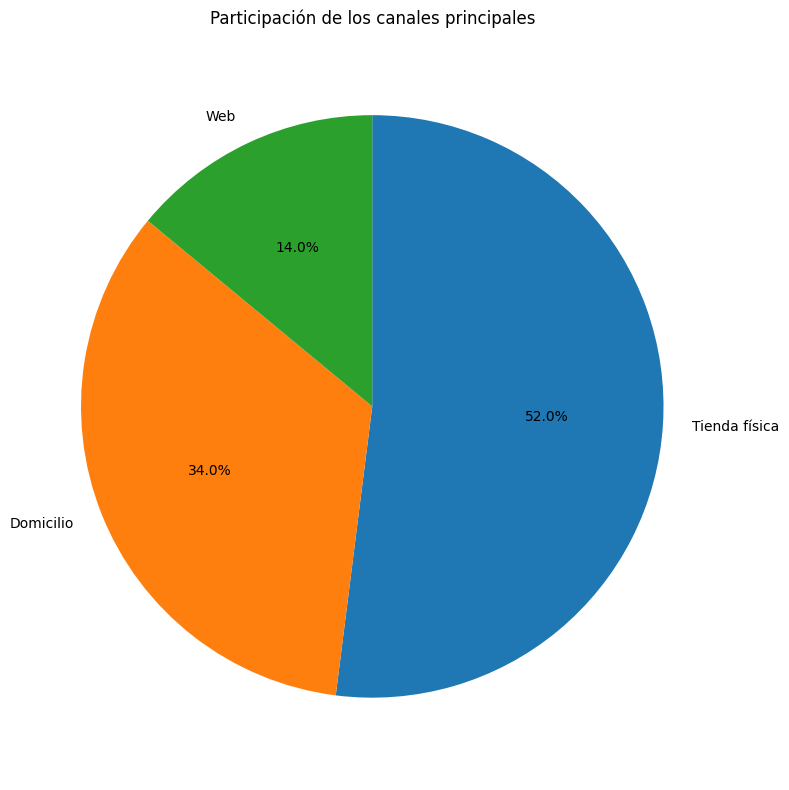

Cantidad de registros por canal principal:
canal_principal
Tienda física    26
Domicilio        17
Web               7
Name: count, dtype: int64

Porcentaje por canal principal:
canal_principal
Tienda física    52.0
Domicilio        34.0
Web              14.0
Name: count, dtype: float64


In [ ]:
# Frecuencia de cada canal principal en los 50 registros semanales
participacion_canales = df["canal_principal"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    participacion_canales.values,
    labels=participacion_canales.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False
)
plt.title("Participación de los canales principales")
plt.axis("equal")
plt.tight_layout()
plt.show()

print("Cantidad de registros por canal principal:")
print(participacion_canales)
print("\nPorcentaje por canal principal:")
print((participacion_canales / participacion_canales.sum() * 100).round(1))


La tienda física es el canal principal en **26 de los 50 registros (52 %)**; domicilio representa 17 registros (34 %) y Web, 7 (14 %). La tienda física predomina en la muestra. La empresa podría analizar oportunidades para fortalecer Web, pero debería evaluar conversión, costos de operación y preferencias por ciudad antes de establecer una meta de crecimiento. Como cada fila representa el canal principal de una sede en una semana, estos porcentajes describen registros semanales y no el porcentaje exacto de todas las transacciones realizadas por canal.


### 3.5 Valor de la analítica y toma de decisiones

## 3.5.1. • Utilice la función calcular_utilidad_modelo(precision, valor_acierto, costo_error)

In [ ]:
def calcular_utilidad_modelo(precision, valor_acierto, costo_error):
  """Calcula la utilidad esperada por campaña evaluada por el modelo."""
  utilidad = (precision * valor_acierto) - ((1 - precision) * costo_error)
  return utilidad


# Evaluación Modelo A (Nacional)
utilidad_A = calcular_utilidad_modelo(
    precision=0.85, valor_acierto=500000, costo_error=400000
)

# Evaluación Modelo B (Prueba piloto local)
utilidad_B = calcular_utilidad_modelo(
    precision=0.78, valor_acierto=500000, costo_error=40000
)

# Impresión de Resultados
print('--- RESULTADOS DE UTILIDAD ESPERADA ---')
print(f'Modelo A (Precisión 85%): ${utilidad_A:,.2f} COP')
print(f'Modelo B (Precisión 78%): ${utilidad_B:,.2f} COP')
print(f'Ganancia adicional al elegir B: ${utilidad_B - utilidad_A:,.2f} COP')

--- RESULTADOS DE UTILIDAD ESPERADA ---
Modelo A (Precisión 85%): $365,000.00 COP
Modelo B (Precisión 78%): $381,200.00 COP
Ganancia adicional al elegir B: $16,200.00 COP


## Conclusión y Decisión Gerencial

- **Modelo a elegir:** Se debe adoptar el **Modelo B**.

- **Justificación Financiera:** Ofrece una utilidad esperada de **$381.200 COP** frente a los **$365.000 COP** del Modelo A, aportando **$16.200 COP adicionales de ganancia neta** por campaña evaluada.

- **Lección de Negocio:** El modelo más preciso no siempre es el más rentable. La asimetría en los costos del error (perder $400.000 en *A* vs*  $40.000 en B) demuestra que mitigar el impacto operativo del fallo mediante pruebas piloto es financieramente más efectivo que buscar únicamente la máxima precisión estadística.

## 3.5.2. Recomendaciones Estratégicas para la Gerencia de Café Aroma Andino

Con base en la integración de los resultados estadísticos, los filtros aplicados y las representaciones gráficas del periodo analizado, se presentan tres recomendaciones de negocio accionables respaldadas por evidencia cuantitativa:

---

# 1. Reasignación Eficiente de la Inversión en Publicidad (Enfoque por Retorno/ROI)

* **Estrategia:** Reasignar progresivamente entre un 15% y un 20% del presupuesto publicitario de la sede Neiva hacia la sede Bogotá.
* **Dato que lo respalda:**
  * **Bogotá** presenta la mayor eficiencia publicitaria de la cadena, generando **$5,19 COP en ingresos por cada $1 COP invertido** en publicidad (Ingresos: $158.581.400 COP | Publicidad: $30.550.000 COP) y el ticket promedio más alto (**$42.814 COP**).
  * **Neiva** registra el retorno publicitario más bajo (**$4,08 COP per peso invertido**), generando ingresos totales de solo $60.523.100 COP.
* **Acción Gerencial:** En Bogotá cada peso publicitario rinde un 27% más que en Neiva. Se recomienda concentrar la pauta en Bogotá para maximizar el margen bruto nacional, mientras que en Neiva se debe migrar de publicidad masiva a estrategias locales de fidelización e incremento de consumo por cliente.

---

# 2. Plan de Choque e Higiene Operativa en Satisfacción (Foco Barranquilla y Cali)

* **Estrategia:** Implementar un plan de auditoría operativa y capacitación en servicio enfocando recursos en la sede Barranquilla.
* **Dato que lo respalda:**
  * **Barranquilla** registra la **satisfacción promedio más baja de toda la empresa (3,89 / 5,0)**, con semanas críticas que descendieron hasta **3,7**.
  * **Cali** ocupa el segundo lugar más bajo en satisfacción (**4,09 / 5,0**), mientras que **Neiva (4,57)** y **Medellín (4,53)** lideran el indicador.
* **Acción Gerencial:** Caer por debajo de 4,0 en la escala de satisfacción genera fuga de clientes hacia la competencia. La gerencia debe evaluar tiempos de entrega, calidad de preparación y atención en el punto de venta de Barranquilla para elevar el indicador por encima de 4,3/5,0 en el próximo trimestre.

---

# 3. Escalamiento del Canal Web e Impulso del Ticket Promedio en Domicilios

* **Estrategia:** Fortalecer la infraestructura del canal **Web** y crear paquetes/combos exclusivos para el canal **Domicilio**.
* **Dato que lo respalda:**
  * El canal **Web** obtiene la **satisfacción promedio más alta entre todos los canales (4,43 / 5,0)**, pero está subexplotado al representar únicamente el 13,2% de los ingresos totales ($73.372.700* COP* con solo 7 registros).
  * El canal **Domicilio** registra el **ticket promedio más elevado por cliente ($42.034 COP)**, superando a la Tienda física ($40.814 COP).
* **Acción Gerencial:** La alta satisfacción en la Web demuestra que los usuarios valoran la experiencia digital. La gerencia debe invertir en promociones para captar más tráfico en la plataforma Web y lanzar productos de mayor valor agregado en Domicilio para consolidar su liderazgo en ticket promedio.

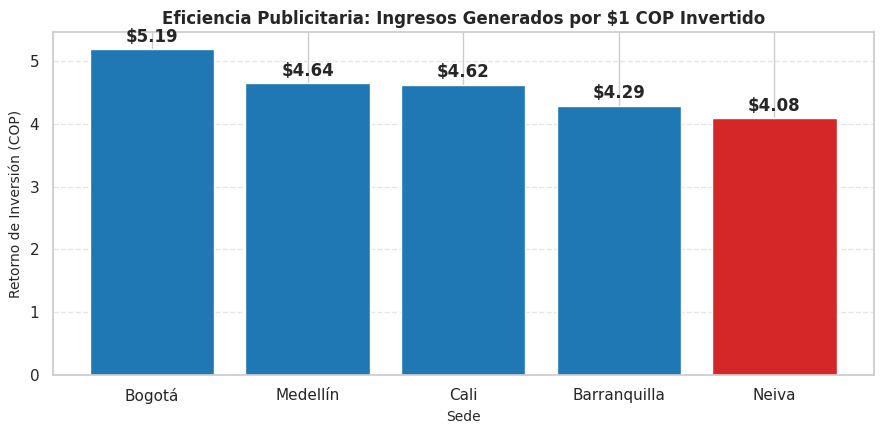

In [ ]:
import matplotlib.pyplot as plt

# 1. Cálculo del ROI (Ingresos por cada peso invertido en publicidad)
sede_summary = (
    df.groupby("sede")
    .agg(
        ingresos_totales=("ingresos", "sum"),
        publicidad_total=("inversion_publicidad", "sum"),
    )
    .reset_index()
)

sede_summary["roi"] = (
    sede_summary["ingresos_totales"] / sede_summary["publicidad_total"]
)
sede_summary = sede_summary.sort_values("roi", ascending=False)

# 2. Creación del gráfico de barras
plt.figure(figsize=(9, 4.5))
colores = [
    "#1f77b4" if s != "Neiva" else "#d62728" for s in sede_summary["sede"]
]
barras = plt.bar(sede_summary["sede"], sede_summary["roi"], color=colores)

# 3. Personalización visual
plt.title(
    "Eficiencia Publicitaria: Ingresos Generados por $1 COP Invertido",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Sede", fontsize=10)
plt.ylabel("Retorno de Inversión (COP)", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Etiquetas numéricas sobre cada barra
for barra in barras:
  yval = barra.get_height()
  plt.text(
      barra.get_x() + barra.get_width() / 2.0,
      yval + 0.05,
      f"${yval:.2f}",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.tight_layout()
plt.show()